# Real Estate Investment Advisor: Exploratory Data Analysis

**Dataset:** `india_housing_prices.csv` (250,000 listings, 22 raw columns, 42 cities across 20 states)
**Goal:** understand what (if anything) drives property prices in this data, so we can later flag good and bad investment decisions.

**Notebook flow**
1. Data preprocessing (quality checks, unit fix, consistency checks, outliers)
2. Feature preprocessing (engineered columns used in the EDA and later in the Streamlit dashboard)
3. EDA (8 focused questions, numbered as in the project brief)
4. Summary and investment implications

**Questions covered:** the brief lists 20 EDA questions. I picked the ones that matter most for an investment decision: Q1, Q4 (price and size), Q6, Q7 (location), Q11, Q14 (feature relationships), Q19, Q20 (amenities and accessibility). Q5 (outliers) is handled inside preprocessing because it directly decides how we treat extreme values.

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
PALETTE = "viridis"
ACCENT = "#2a6f97"
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

REFERENCE_YEAR = 2025  # Age_of_Property is computed against this year in the raw data

In [2]:
from pathlib import Path

# Works whether the csv sits next to the notebook or inside a data/ folder
for p in ["india_housing_prices.csv", "data/india_housing_prices.csv",
          "data/raw/india_housing_prices.csv.gz", "../data/raw/india_housing_prices.csv.gz"]:
    if Path(p).exists():
        DATA_PATH = p
        break
else:
    raise FileNotFoundError("Put india_housing_prices.csv next to this notebook, or keep the repo layout (data/raw/)")

df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loaded ../data/raw/india_housing_prices.csv.gz: 250,000 rows x 23 columns


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


## 1. Data Preprocessing

### 1.1 Structure and data types

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  str    
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors               

### 1.2 Missing values, duplicates and category hygiene

In [4]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs :", df["ID"].duplicated().sum())

# stray whitespace / inconsistent casing in text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    cleaned = df[c].str.strip()
    if not cleaned.equals(df[c]):
        print(f"Whitespace found in {c}, stripping")
        df[c] = cleaned

quality

Duplicate rows: 0
Duplicate IDs : 0


,missing,missing_%,unique_values
ID,0,0.00,250000
State,0,0.00,20
City,0,0.00,42
Locality,0,0.00,500
Property_Type,0,0.00,3
BHK,0,0.00,5
Size_in_SqFt,0,0.00,4501
Price_in_Lakhs,0,0.00,48700
Price_per_SqFt,0,0.00,100
Year_Built,0,0.00,34


No missing values, no duplicate rows or IDs, and the text columns are already clean. The categorical columns have small, consistent label sets, so no recoding is needed.

### 1.3 Unit check on `Price_per_SqFt`
The raw `Price_per_SqFt` column holds values like 0.10 and 0.04. That is because price is in **lakhs** and the ratio was rounded to 2 decimals, so it is really lakhs per sq ft. Rounded that hard, it loses most of its information, and thousands of rows collapse to 0.00. I verify this and rebuild the column in rupees per sq ft.

In [5]:
raw_ppsf = df["Price_per_SqFt"]
ppsf_rs = df["Price_in_Lakhs"] * 100_000 / df["Size_in_SqFt"]   # 1 lakh = 100,000 rupees

print("Max gap between raw column and Price/Size (in lakhs per sqft):",
      round((df["Price_in_Lakhs"] / df["Size_in_SqFt"] - raw_ppsf).abs().max(), 4))
print(f"Rows where raw Price_per_SqFt is exactly 0.00: {(raw_ppsf == 0).sum():,}")
print(f"Distinct values in raw column: {raw_ppsf.nunique()}  vs  rebuilt column: {ppsf_rs.round(0).nunique():,}")

df["Price_per_SqFt_Rs"] = ppsf_rs.round(2)

Max gap between raw column and Price/Size (in lakhs per sqft): 0.005
Rows where raw Price_per_SqFt is exactly 0.00: 2,534
Distinct values in raw column: 100  vs  rebuilt column: 45,603


Confirmed. The raw column is just `Price_in_Lakhs / Size_in_SqFt` rounded to two decimals. From here on I use `Price_per_SqFt_Rs` (rupees per sq ft) and drop the raw one in the feature step.

### 1.4 Logical consistency checks
Before analysing anything, I test whether the columns agree with each other.

In [6]:
checks = {
    "Age + Year_Built equals 2025 for every row":
        (df["Age_of_Property"] + df["Year_Built"] == REFERENCE_YEAR).mean(),
    "Floor_No is higher than Total_Floors (impossible)":
        (df["Floor_No"] > df["Total_Floors"]).mean(),
    "Under construction but older than 5 years":
        ((df["Availability_Status"] == "Under_Construction") & (df["Age_of_Property"] > 5)).mean(),
    "Independent House or Villa listed above floor 1":
        (df["Property_Type"].isin(["Independent House", "Villa"]) & (df["Floor_No"] > 1)).mean(),
    "Ground floor (Floor_No = 0) share":
        (df["Floor_No"] == 0).mean(),
}
pd.Series({k: f"{v:.1%}" for k, v in checks.items()}, name="share of rows").to_frame()

,share of rows
Age + Year_Built equals 2025 for every row,100.0%
Floor_No is higher than Total_Floors (impossible),46.5%
Under construction but older than 5 years,44.1%
Independent House or Villa listed above floor 1,62.5%
Ground floor (Floor_No = 0) share,3.3%


In [7]:
# BHK vs size: if the data were realistic, bigger homes would have more bedrooms
print(df.groupby("BHK")["Size_in_SqFt"].mean().round(0).rename("mean size (sqft)").to_frame().T)

# Same 500 locality names reused in every city?
print("\nCities per locality name (min / max):",
      df.groupby("Locality")["City"].nunique().min(), "/", df.groupby("Locality")["City"].nunique().max())

BHK                     1        2        3        4        5
mean size (sqft) 2,750.00 2,752.00 2,750.00 2,753.00 2,745.00

Cities per locality name (min / max): 41 / 42


**What this tells us (worth stating plainly):**
- `Age_of_Property` is just `2025 - Year_Built`, so the two are the same information. I keep `Age_of_Property` for analysis.
- About **46.5% of rows have `Floor_No` above `Total_Floors`**, which cannot happen in reality. Dropping nearly half the dataset would be worse than the problem, so I **flag these rows** (`Floor_Valid`) and keep floor columns out of the analysis.
- About **44% of "Under Construction" listings are older than 5 years**, which is also contradictory. I flag them (`Status_Age_Conflict`) and avoid reading anything into `Age_of_Property` by availability status.
- Average size is the same for 1 BHK and 5 BHK homes, and the same 500 locality names appear in all 42 cities. So `Locality` is a label, not a real place, and I will not draw locality-level conclusions.

These patterns point to a **simulated dataset**, where columns were generated independently. I keep that in mind when interpreting results, and the summary at the end comes back to it.

In [8]:
df["Floor_Valid"] = (df["Floor_No"] <= df["Total_Floors"]).astype(int)
df["Status_Age_Conflict"] = ((df["Availability_Status"] == "Under_Construction") &
                             (df["Age_of_Property"] > 5)).astype(int)
print(df[["Floor_Valid", "Status_Age_Conflict"]].mean().round(3))

Floor_Valid           0.54
Status_Age_Conflict   0.44
dtype: float64


### 1.5 Outlier check on price, size and price per sq ft (Brief Q5)
I use the standard 1.5 x IQR rule on all three.

,min,max,lower fence,upper fence,below fence,above fence,outlier %
Price (lakhs),10.00,500.00,-233.94,743.38,0.00,0.00,0.00
Size (sqft),500.00,"5,000.00","-1,753.50","7,250.50",0.00,0.00,0.00
Price per sqft (Rs),202.25,"99,182.00","-11,973.99","32,764.22",0.00,"19,723.00",7.89


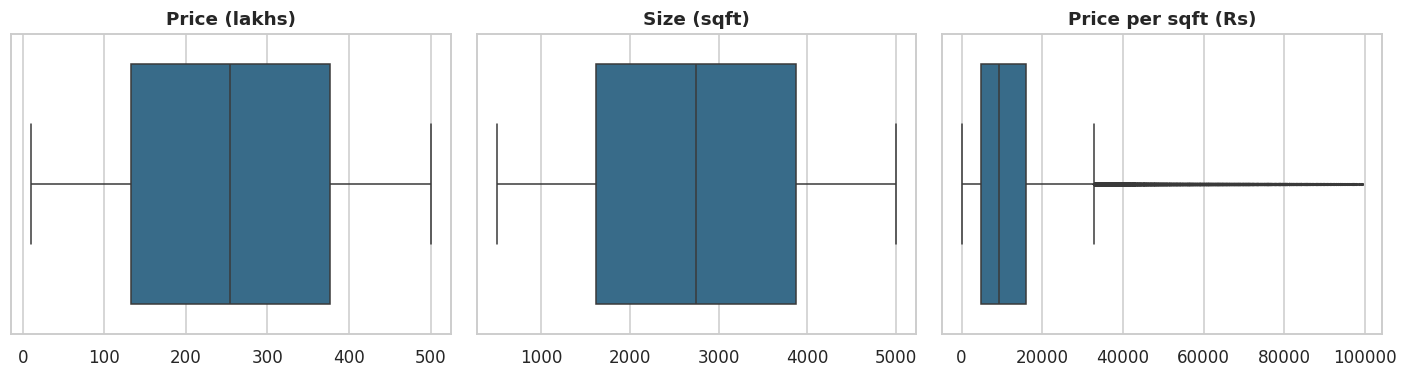

In [9]:
def iqr_report(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {"min": s.min(), "max": s.max(), "lower fence": lo, "upper fence": hi,
            "below fence": int((s < lo).sum()), "above fence": int((s > hi).sum()),
            "outlier %": round(((s < lo) | (s > hi)).mean() * 100, 2)}

outlier_table = pd.DataFrame({
    "Price (lakhs)": iqr_report(df["Price_in_Lakhs"]),
    "Size (sqft)": iqr_report(df["Size_in_SqFt"]),
    "Price per sqft (Rs)": iqr_report(df["Price_per_SqFt_Rs"]),
}).T
display(outlier_table)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
sns.boxplot(x=df["Price_in_Lakhs"], ax=axes[0], color=ACCENT, fliersize=1)
axes[0].set_title("Price (lakhs)")
sns.boxplot(x=df["Size_in_SqFt"], ax=axes[1], color=ACCENT, fliersize=1)
axes[1].set_title("Size (sqft)")
sns.boxplot(x=df["Price_per_SqFt_Rs"], ax=axes[2], color=ACCENT, fliersize=1)
axes[2].set_title("Price per sqft (Rs)")
for a in axes: a.set_xlabel("")
plt.tight_layout(); plt.show()

**Decision:**
- **Price and size have no outliers.** Both sit inside hard limits (10 to 500 lakhs, 500 to 5,000 sqft) with an even spread.
- **Price per sq ft has a long right tail** (about 8% of rows above the upper fence, none below). These are small properties with high prices, which is a valid combination in this data, not an entry error. I do not delete them. I flag them (`PPSF_Outlier`) and use **medians and log scales** whenever price per sq ft is compared across groups, so the tail does not distort the picture.

In [10]:
q1, q3 = df["Price_per_SqFt_Rs"].quantile([0.25, 0.75])
df["PPSF_Outlier"] = (df["Price_per_SqFt_Rs"] > q3 + 1.5 * (q3 - q1)).astype(int)
print(f"Flagged {df['PPSF_Outlier'].sum():,} rows ({df['PPSF_Outlier'].mean():.1%}) as high price-per-sqft outliers")

Flagged 19,723 rows (7.9%) as high price-per-sqft outliers


## 2. Feature Preprocessing
Engineered columns, each with a clear job in the analysis or the dashboard:

| Feature | How it is built | Why it is needed |
|---|---|---|
| `Price_per_SqFt_Rs` | Price x 100,000 / size | Correct-unit value metric (done above) |
| `Amenity_Count`, `Has_<amenity>` | Parsed from the comma-separated `Amenities` text | Lets us measure amenities numerically (Q19) |
| `Transport_Score` | Low = 1, Medium = 2, High = 3 | Ordered version of public transport access (Q11, Q20) |
| `Parking_Flag`, `Security_Flag` | Yes = 1, No = 0 | Numeric form for the correlation matrix |
| `Age_Group`, `Size_Category`, `Price_Segment` | Bins and tertiles | Readable groups for charts and dashboard filters |
| `City_Median_PPSF`, `PPSF_vs_City`, `Below_City_Median` | Property price per sq ft compared with its own city median | A simple relative-value screen for investment |

In [11]:
# Amenities: parse the text into a count and one flag per amenity
AMENITIES = sorted({a for row in df["Amenities"] for a in row.split(", ")})
print("Amenity types found:", AMENITIES)

df["Amenity_Count"] = df["Amenities"].str.split(", ").str.len()
for a in AMENITIES:
    df[f"Has_{a}"] = df["Amenities"].str.contains(a, regex=False).astype(int)

# Ordered / binary encodings
df["Transport_Score"] = df["Public_Transport_Accessibility"].map({"Low": 1, "Medium": 2, "High": 3})
df["Parking_Flag"] = df["Parking_Space"].map({"No": 0, "Yes": 1})
df["Security_Flag"] = df["Security"].map({"No": 0, "Yes": 1})

# Readable groups
df["Age_Group"] = pd.cut(df["Age_of_Property"], bins=[0, 10, 20, 30, 35],
                         labels=["0-10 yrs", "11-20 yrs", "21-30 yrs", "31-35 yrs"])
df["Size_Category"] = pd.cut(df["Size_in_SqFt"], bins=[0, 1500, 2500, 3500, 5000],
                             labels=["Up to 1,500", "1,500-2,500", "2,500-3,500", "3,500+"])
df["Price_Segment"] = pd.qcut(df["Price_in_Lakhs"], 3, labels=["Budget", "Mid-range", "Premium"])

# Relative value inside each city
df["City_Median_PPSF"] = df.groupby("City")["Price_per_SqFt_Rs"].transform("median")
df["PPSF_vs_City"] = (df["Price_per_SqFt_Rs"] / df["City_Median_PPSF"]).round(3)
df["Below_City_Median"] = (df["PPSF_vs_City"] < 1).astype(int)

# The raw lakhs-per-sqft column is superseded by Price_per_SqFt_Rs
df = df.drop(columns=["Price_per_SqFt"])

print(f"\nFinal shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df[["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_Rs", "Amenity_Count", "Transport_Score",
    "Age_Group", "Size_Category", "Price_Segment", "PPSF_vs_City", "Below_City_Median"]].head()

Amenity types found: ['Clubhouse', 'Garden', 'Gym', 'Playground', 'Pool']



Final shape: 250,000 rows x 41 columns


,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt_Rs,Amenity_Count,Transport_Score,Age_Group,Size_Category,Price_Segment,PPSF_vs_City,Below_City_Median
0,489.76,4740,"10,332.49",5,3,31-35 yrs,"3,500+",Premium,1.11,0
1,195.52,2364,"8,270.73",5,1,11-20 yrs,"1,500-2,500",Mid-range,0.87,1
2,183.79,3642,"5,046.40",4,1,21-30 yrs,"3,500+",Mid-range,0.55,1
3,300.29,2741,"10,955.49",5,3,31-35 yrs,"2,500-3,500",Mid-range,1.18,0
4,182.90,4823,"3,792.25",5,1,21-30 yrs,"3,500+",Mid-range,0.42,1


In [12]:
# Save the cleaned dataset for the Streamlit stage (into the repo data/ folder when run from notebooks/)
OUT_PATH = "../data/housing_clean.csv.gz" if Path("../data").exists() else "housing_clean.csv"
df.to_csv(OUT_PATH, index=False)
print("Saved", OUT_PATH)

Saved ../data/housing_clean.csv.gz


`Year_Built` and `Age_of_Property` carry identical information, so only one should go into any model later. For the EDA below it makes no difference.

## 3. Exploratory Data Analysis

Throughout, I test every comparison with a statistical test and also report **effect size**. With 250,000 rows even tiny differences can look "significant", so effect size (eta squared, the share of variation a factor explains) is what tells us whether a difference is large enough to act on.

In [13]:
def anova_eta(data, group, value, log=False):
    """One-way ANOVA plus eta squared (share of variance explained by the grouping)."""
    x = np.log10(data[value]) if log else data[value]
    groups = [x[data[group] == k] for k in data[group].unique()]
    F, p = stats.f_oneway(*groups)
    grand = x.mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((x - grand) ** 2).sum()
    eta2 = ss_between / ss_total
    print(f"ANOVA {group} -> {value}{' (log)' if log else ''}: F = {F:.2f}, p = {p:.4f}, "
          f"eta squared = {eta2:.5f} ({eta2:.4%} of variation explained)")
    return F, p, eta2

rs = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}")

### Price and Size

#### Q1. What is the distribution of property prices?
I look at both the listing price and price per sq ft, since price per sq ft is the number an investor compares.

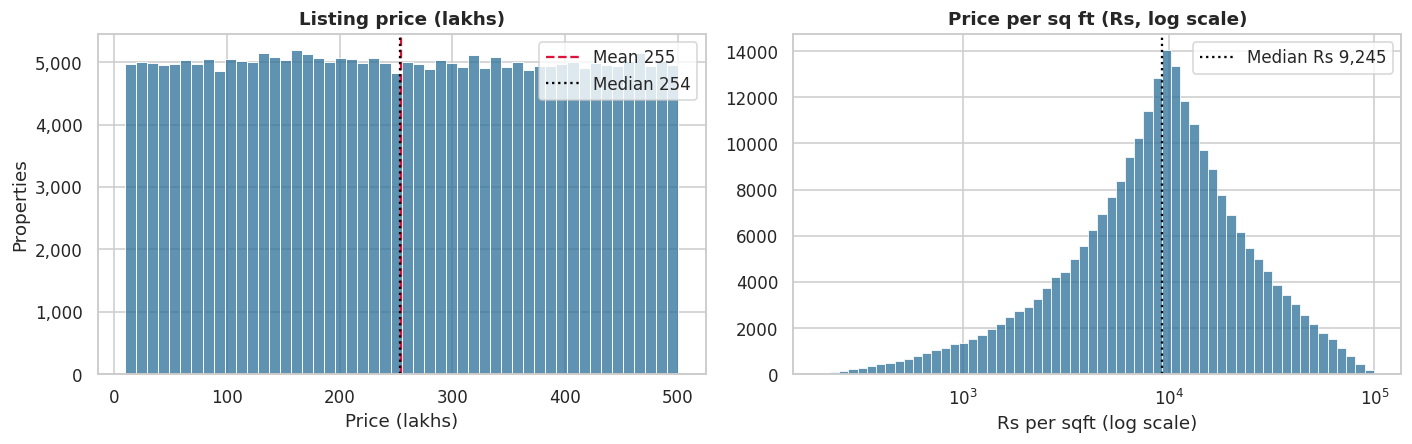

       Price_in_Lakhs  Price_per_SqFt_Rs
count      250,000.00         250,000.00
mean           254.60          13,058.30
std            141.30          13,071.90
min             10.00             202.20
5%              34.60           1,252.40
25%            132.60           4,802.80
50%            253.90           9,244.80
75%            376.90          15,987.40
95%            475.40          40,569.00
max            500.00          99,182.00

Skewness: {'Price_in_Lakhs': 0.01, 'Price_per_SqFt_Rs': 2.32}


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(df["Price_in_Lakhs"], bins=50, color=ACCENT, ax=axes[0])
axes[0].axvline(df["Price_in_Lakhs"].mean(), color="crimson", ls="--", label=f"Mean {df['Price_in_Lakhs'].mean():.0f}")
axes[0].axvline(df["Price_in_Lakhs"].median(), color="black", ls=":", label=f"Median {df['Price_in_Lakhs'].median():.0f}")
axes[0].set(title="Listing price (lakhs)", xlabel="Price (lakhs)", ylabel="Properties")
axes[0].yaxis.set_major_formatter(rs); axes[0].legend()

sns.histplot(df["Price_per_SqFt_Rs"], bins=60, log_scale=True, color=ACCENT, ax=axes[1])
axes[1].axvline(df["Price_per_SqFt_Rs"].median(), color="black", ls=":",
                label=f"Median Rs {df['Price_per_SqFt_Rs'].median():,.0f}")
axes[1].set(title="Price per sq ft (Rs, log scale)", xlabel="Rs per sqft (log scale)", ylabel="")
axes[1].legend()
plt.tight_layout(); plt.show()

print(df[["Price_in_Lakhs", "Price_per_SqFt_Rs"]].describe(percentiles=[.05, .25, .5, .75, .95]).round(1))
print("\nSkewness:", df[["Price_in_Lakhs", "Price_per_SqFt_Rs"]].skew().round(2).to_dict())

**Takeaway**
- **Listing price is almost flat across its range**: mean and median are both around 254 lakhs, skewness is about zero, and the histogram is nearly rectangular from 10 to 500 lakhs. There is no "typical" price band, and no cluster of cheap or premium homes.
- **Price per sq ft is heavily right-skewed**: the median is around Rs 9,200 but the mean is Rs 13,000, pulled up by small properties with high prices. Because of this skew, medians are the right summary for price per sq ft in every comparison below.

#### Q4. Is there a relationship between property size and price?
This is the most important check in the whole notebook. If size does not drive price, the pricing logic of the dataset is very different from a real market.

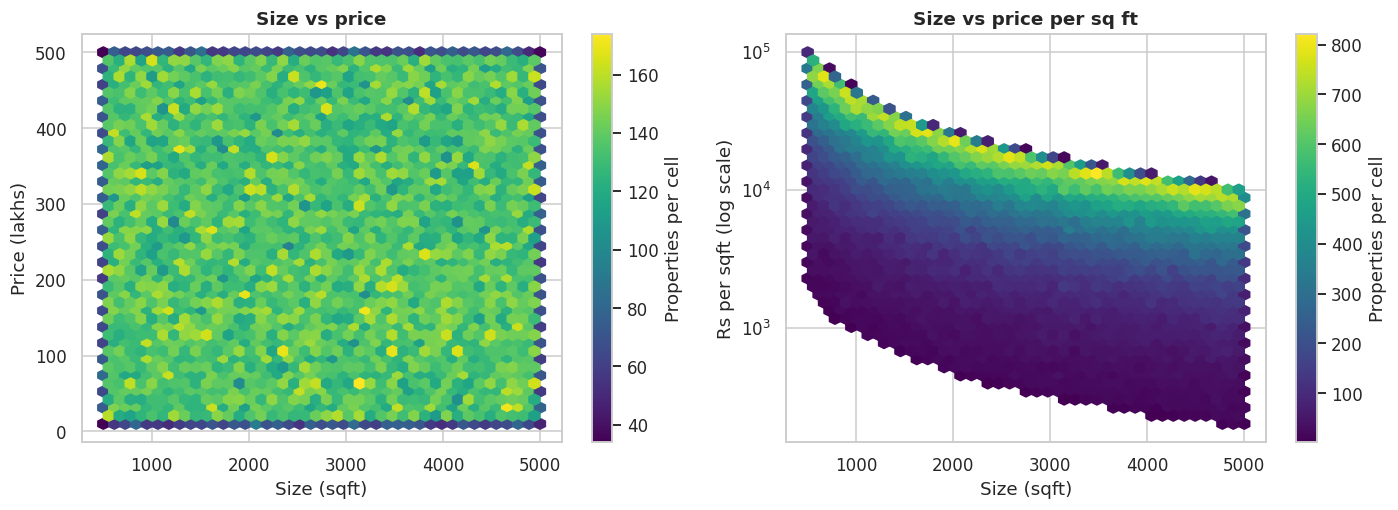

Size vs Price         : Pearson r = -0.003 (p = 0.21), Spearman rho = -0.003 (p = 0.21)
Size vs Price per sqft: Spearman rho = -0.599


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

hb = axes[0].hexbin(df["Size_in_SqFt"], df["Price_in_Lakhs"], gridsize=40, cmap=PALETTE, mincnt=1)
axes[0].set(title="Size vs price", xlabel="Size (sqft)", ylabel="Price (lakhs)")
plt.colorbar(hb, ax=axes[0], label="Properties per cell")

hb2 = axes[1].hexbin(df["Size_in_SqFt"], df["Price_per_SqFt_Rs"], gridsize=40, yscale="log", cmap=PALETTE, mincnt=1)
axes[1].set(title="Size vs price per sq ft", xlabel="Size (sqft)", ylabel="Rs per sqft (log scale)")
plt.colorbar(hb2, ax=axes[1], label="Properties per cell")
plt.tight_layout(); plt.show()

r_p, p_p = stats.pearsonr(df["Size_in_SqFt"], df["Price_in_Lakhs"])
r_s, p_s = stats.spearmanr(df["Size_in_SqFt"], df["Price_in_Lakhs"])
r_pp, _ = stats.spearmanr(df["Size_in_SqFt"], df["Price_per_SqFt_Rs"])
print(f"Size vs Price         : Pearson r = {r_p:.3f} (p = {p_p:.2f}), Spearman rho = {r_s:.3f} (p = {p_s:.2f})")
print(f"Size vs Price per sqft: Spearman rho = {r_pp:.3f}")

**Takeaway**
- **Size and price are unrelated** (r = -0.003, p = 0.2). A 500 sq ft property and a 5,000 sq ft property have the same expected price. In a real market this correlation is usually strongly positive, so this is a major finding about how the data behaves.
- The right chart shows the consequence: price per sq ft falls steeply as size rises, in a hyperbola shape. That is purely arithmetic (a fixed price spread over more area), not a market effect. Larger properties look "cheaper per sq ft" only because price does not rise with size here.
- This matters for later work: any "good deal" rule based on price per sq ft will mostly be selecting large properties.

### Location

#### Q6. What is the average price per sq ft by state?
Bars start at zero on purpose, so the visual size of the differences matches their real size.

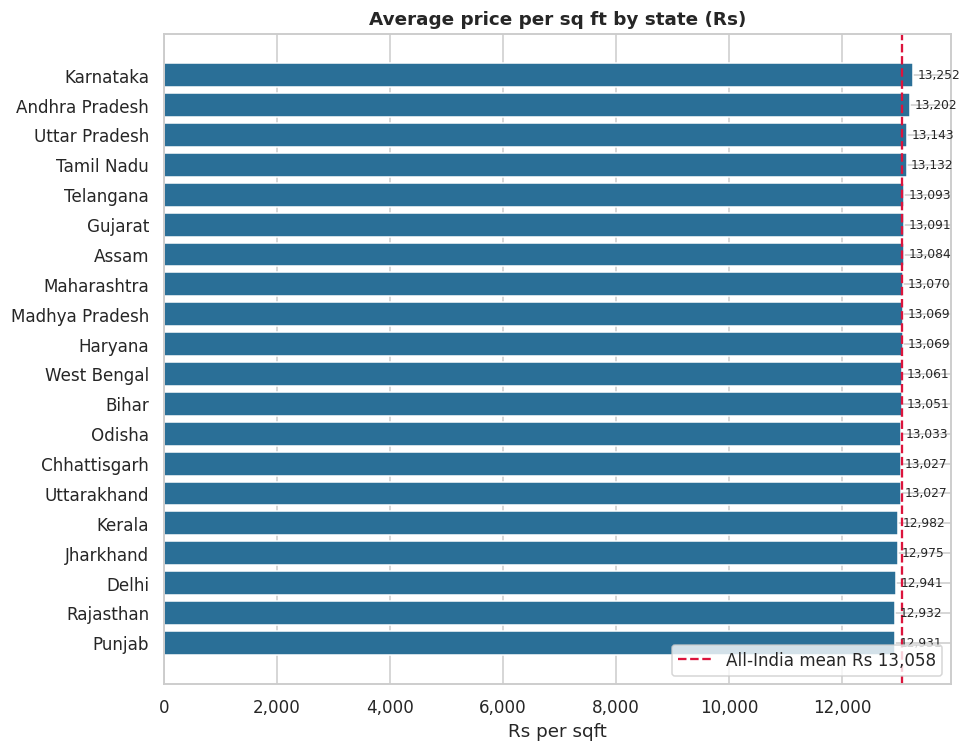

Highest: Karnataka (Rs 13,252) | Lowest: Punjab (Rs 12,931) | spread: 2.5%
ANOVA State -> Price_per_SqFt_Rs (log): F = 0.84, p = 0.6648, eta squared = 0.00006 (0.0064% of variation explained)


In [16]:
state_ppsf = (df.groupby("State")["Price_per_SqFt_Rs"].agg(["mean", "median", "count"])
                .sort_values("mean"))
overall = df["Price_per_SqFt_Rs"].mean()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(state_ppsf.index, state_ppsf["mean"], color=ACCENT)
ax.axvline(overall, color="crimson", ls="--", label=f"All-India mean Rs {overall:,.0f}")
for i, v in enumerate(state_ppsf["mean"]):
    ax.text(v + 80, i, f"{v:,.0f}", va="center", fontsize=8)
ax.set(title="Average price per sq ft by state (Rs)", xlabel="Rs per sqft", ylabel="")
ax.xaxis.set_major_formatter(rs); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

spread = state_ppsf["mean"].max() / state_ppsf["mean"].min() - 1
print(f"Highest: {state_ppsf['mean'].idxmax()} (Rs {state_ppsf['mean'].max():,.0f}) | "
      f"Lowest: {state_ppsf['mean'].idxmin()} (Rs {state_ppsf['mean'].min():,.0f}) | spread: {spread:.1%}")
anova_eta(df, "State", "Price_per_SqFt_Rs", log=True);

**Takeaway**
- Every state sits within a few percent of the all-India average, so the ranking is real on paper but tiny in size. The gap between the "most expensive" and "cheapest" state is only a few percent.
- The test agrees: state explains about 0.006% of the variation in price per sq ft (p = 0.66, not significant). **State is not a useful lever for picking an investment in this data.** In real Indian markets, state-to-state gaps in price per sq ft are usually far larger than this.

#### Q7. What is the average property price by city?
With 42 cities, I plot each city's mean with a 95% confidence interval. If the intervals overlap, the cities cannot be told apart.

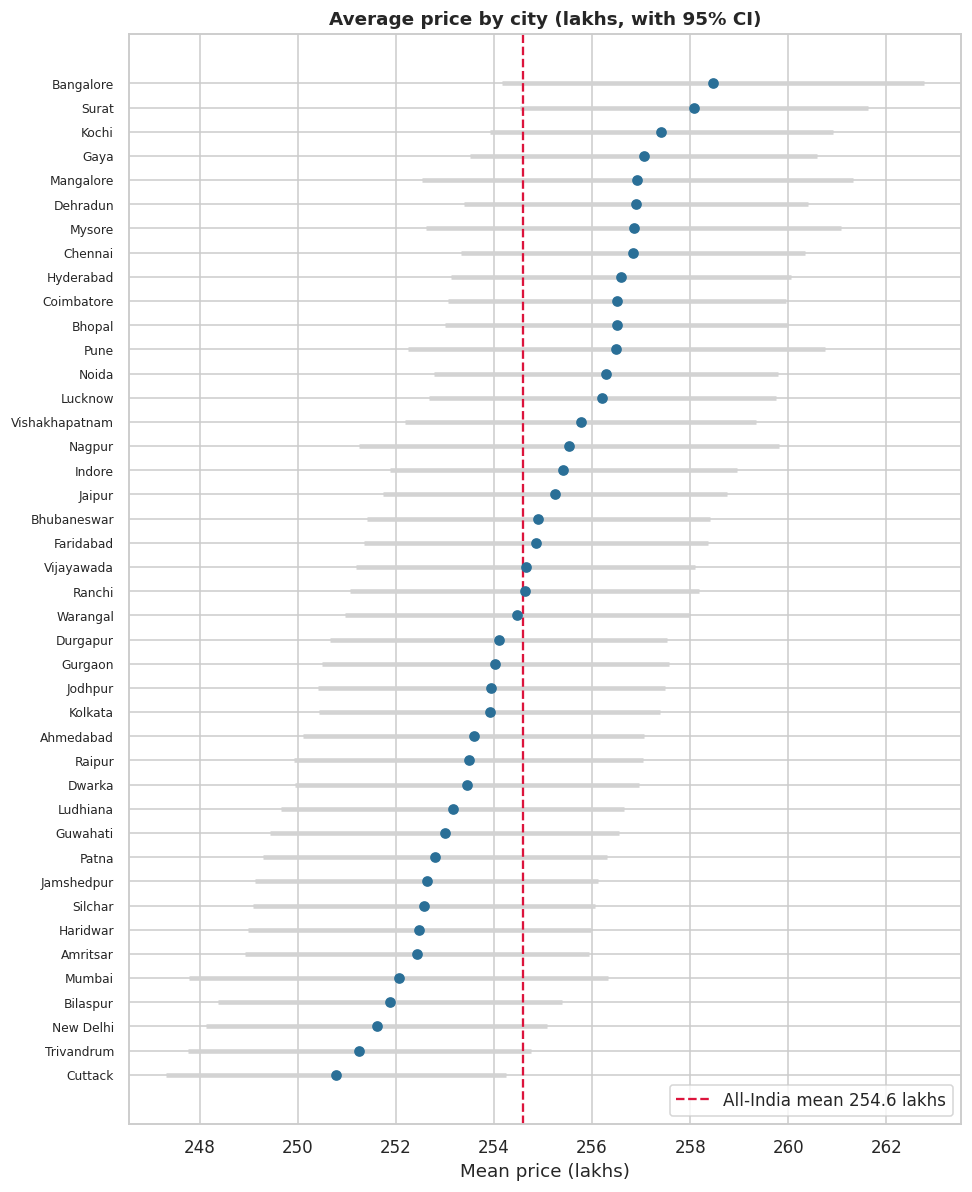

Top 3 cities   : {'Kochi': 257.4, 'Surat': 258.1, 'Bangalore': 258.5}
Bottom 3 cities: {'Cuttack': 250.8, 'Trivandrum': 251.3, 'New Delhi': 251.6}
Gap top vs bottom: 3.1%
ANOVA City -> Price_in_Lakhs: F = 1.16, p = 0.2232, eta squared = 0.00019 (0.0190% of variation explained)


In [17]:
city = df.groupby("City")["Price_in_Lakhs"].agg(["mean", "sem", "count"]).sort_values("mean")
city["ci"] = 1.96 * city["sem"]
overall_price = df["Price_in_Lakhs"].mean()

fig, ax = plt.subplots(figsize=(9, 11))
ax.errorbar(city["mean"], range(len(city)), xerr=city["ci"], fmt="o", color=ACCENT,
            ecolor="lightgray", elinewidth=3, capsize=0)
ax.axvline(overall_price, color="crimson", ls="--", label=f"All-India mean {overall_price:.1f} lakhs")
ax.set_yticks(range(len(city))); ax.set_yticklabels(city.index, fontsize=8)
ax.set(title="Average price by city (lakhs, with 95% CI)", xlabel="Mean price (lakhs)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"Top 3 cities   : {city['mean'].tail(3).round(1).to_dict()}")
print(f"Bottom 3 cities: {city['mean'].head(3).round(1).to_dict()}")
print(f"Gap top vs bottom: {city['mean'].max() / city['mean'].min() - 1:.1%}")
anova_eta(df, "City", "Price_in_Lakhs");

**Takeaway**
- City averages range only from about 251 to 258 lakhs, a gap of roughly 3%. 41 of the 42 confidence intervals overlap the all-India mean (only Cuttack falls just outside, which is about what chance alone would give across 42 cities), so the cities are statistically indistinguishable.
- City explains about 0.02% of price variation (p = 0.22). Mumbai, Delhi and a tier-3 city like Silchar price the same here, which does not match real markets. **A city-level ranking from this data would be noise, not insight**, so the dashboard should not present one as a finding.

### Feature Relationships

#### Q11. How are numeric features correlated with each other?
Spearman correlation is used because price per sq ft is skewed. Floor columns are left out because of the consistency problem found in 1.4.

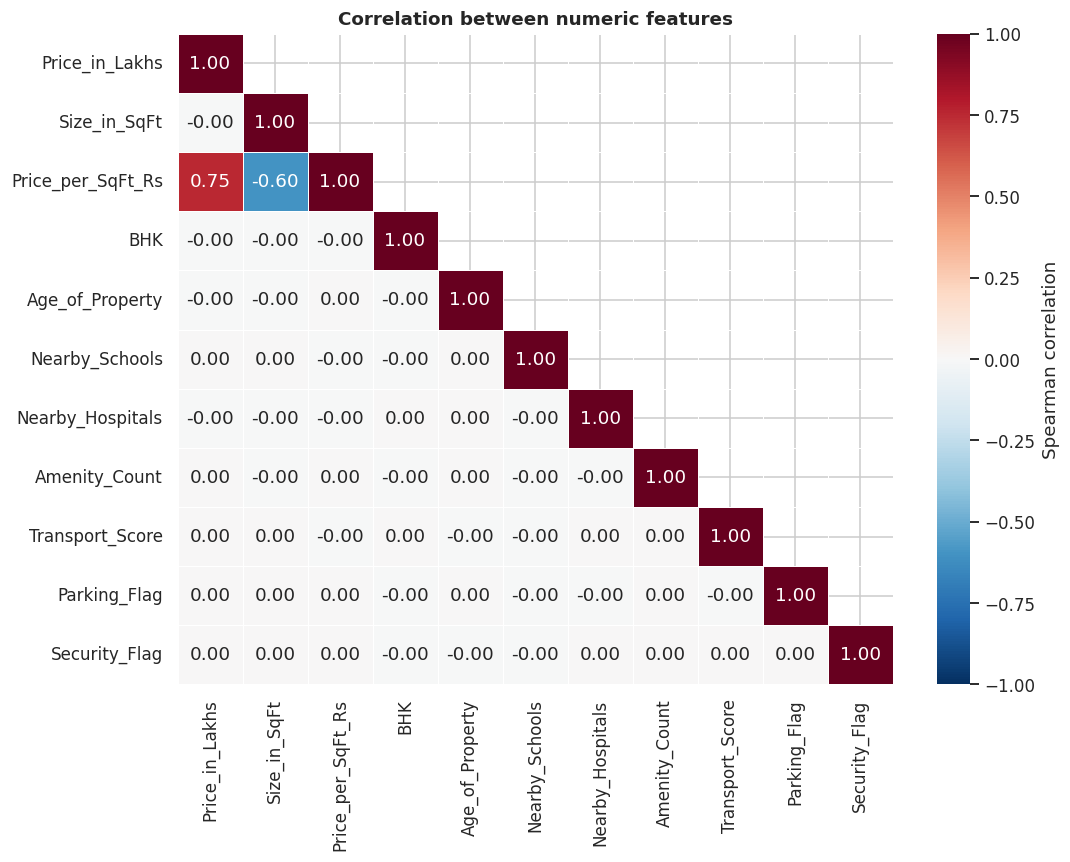

Pairs with |rho| above 0.05:


,feature_a,feature_b,rho
22,Price_per_SqFt_Rs,Price_in_Lakhs,0.75
23,Price_per_SqFt_Rs,Size_in_SqFt,-0.60


In [18]:
num_cols = ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_Rs", "BHK", "Age_of_Property",
            "Nearby_Schools", "Nearby_Hospitals", "Amenity_Count", "Transport_Score",
            "Parking_Flag", "Security_Flag"]
corr = df[num_cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Correlation between numeric features")
plt.tight_layout(); plt.show()

pairs = (corr.where(~mask & (corr != 1)).stack().rename("rho").reset_index()
             .query("abs(rho) > 0.05").sort_values("rho", key=abs, ascending=False))
pairs.columns = ["feature_a", "feature_b", "rho"]
print("Pairs with |rho| above 0.05:")
pairs

**Takeaway**
- Only two relationships stand out, and both are **built into the formula**: price per sq ft rises with price and falls with size, because it equals price divided by size.
- Every other pair is essentially zero: price does not move with size, BHK, age, schools, hospitals, amenities, transport, parking or security. BHK is also unrelated to size, which would not happen in a real listing set.
- In practical terms, **no listed feature predicts price**. That limits what any later model can learn from this data, and it is worth stating up front in the report.

#### Q14. How does price vary by furnished status?

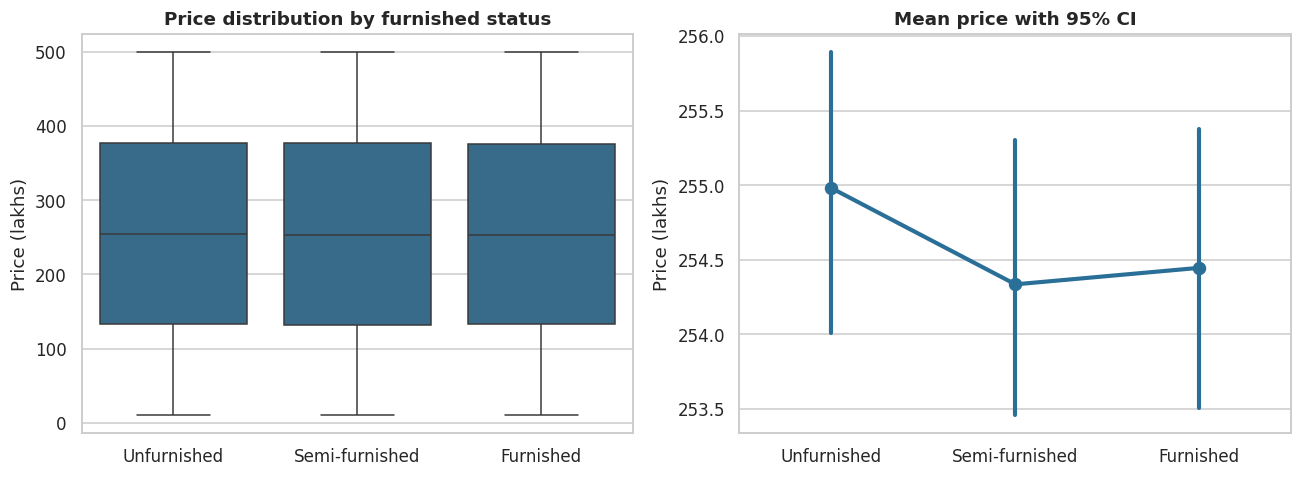

                   mean  median  count
Furnished_Status                      
Unfurnished      255.00  254.20  83408
Semi-furnished   254.30  253.80  83374
Furnished        254.40  253.60  83218
ANOVA Furnished_Status -> Price_in_Lakhs: F = 0.50, p = 0.6088, eta squared = 0.00000 (0.0004% of variation explained)


In [19]:
order = ["Unfurnished", "Semi-furnished", "Furnished"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", order=order, color=ACCENT,
            showfliers=False, ax=axes[0])
axes[0].set(title="Price distribution by furnished status", xlabel="", ylabel="Price (lakhs)")

sns.pointplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", order=order, errorbar=("ci", 95),
              color=ACCENT, ax=axes[1])
axes[1].set(title="Mean price with 95% CI", xlabel="", ylabel="Price (lakhs)")
plt.tight_layout(); plt.show()

print(df.groupby("Furnished_Status")["Price_in_Lakhs"].agg(["mean", "median", "count"]).loc[order].round(1))
anova_eta(df, "Furnished_Status", "Price_in_Lakhs");

**Takeaway**
Furnished, semi-furnished and unfurnished properties have the same price distribution (means within about 1 lakh of each other, p = 0.61). **Furnishing carries no price premium in this data.** In the real market a furnished flat usually sells or rents for more, so this is another sign that prices were not generated from these features.

### Investment, Amenities and Ownership

#### Q19. How do amenities affect price per sq ft?
Two views: how price per sq ft changes with the number of amenities, and how much each individual amenity adds or removes.

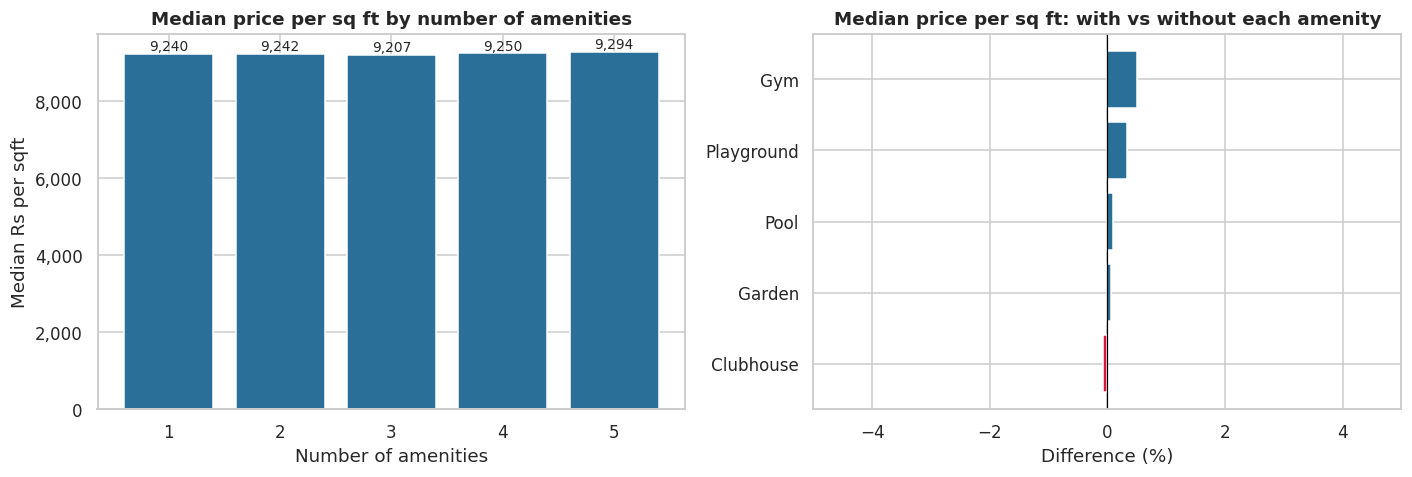

Per-amenity difference in median price per sqft (%): {'Clubhouse': -0.08, 'Garden': 0.06, 'Pool': 0.09, 'Playground': 0.34, 'Gym': 0.5}
ANOVA Amenity_Count -> Price_per_SqFt_Rs (log): F = 0.86, p = 0.4844, eta squared = 0.00001 (0.0014% of variation explained)


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

by_count = df.groupby("Amenity_Count")["Price_per_SqFt_Rs"].median()
axes[0].bar(by_count.index.astype(str), by_count.values, color=ACCENT)
for i, v in enumerate(by_count.values):
    axes[0].text(i, v + 80, f"{v:,.0f}", ha="center", fontsize=9)
axes[0].set(title="Median price per sq ft by number of amenities", xlabel="Number of amenities", ylabel="Median Rs per sqft")
axes[0].yaxis.set_major_formatter(rs)

effects = {}
for a in AMENITIES:
    has = df.loc[df[f"Has_{a}"] == 1, "Price_per_SqFt_Rs"].median()
    no = df.loc[df[f"Has_{a}"] == 0, "Price_per_SqFt_Rs"].median()
    effects[a] = (has / no - 1) * 100
eff = pd.Series(effects).sort_values()
axes[1].barh(eff.index, eff.values, color=[ACCENT if v >= 0 else "crimson" for v in eff.values])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(title="Median price per sq ft: with vs without each amenity", xlabel="Difference (%)", ylabel="")
axes[1].set_xlim(-5, 5)
plt.tight_layout(); plt.show()

print("Per-amenity difference in median price per sqft (%):", eff.round(2).to_dict())
anova_eta(df, "Amenity_Count", "Price_per_SqFt_Rs", log=True);

**Takeaway**
- The number of amenities does not move price per sq ft (the medians for 1 to 5 amenities are all within about 1% of each other; p = 0.48).
- No single amenity shifts it by more than about half a percent, in either direction. The x-axis of the right chart is set to plus or minus 5% on purpose, to show how small these effects really are.
- For an investor, this means that **in this data amenities are essentially free**: a property with a pool, gym and clubhouse costs no more per sq ft than one with none.

#### Q20. How does public transport accessibility relate to price per sq ft and investment potential?
For "investment potential" I use the relative-value flag built earlier: the share of properties priced **below their own city's median price per sq ft**. Under a coin-flip pricing process that share would be about 50% everywhere.

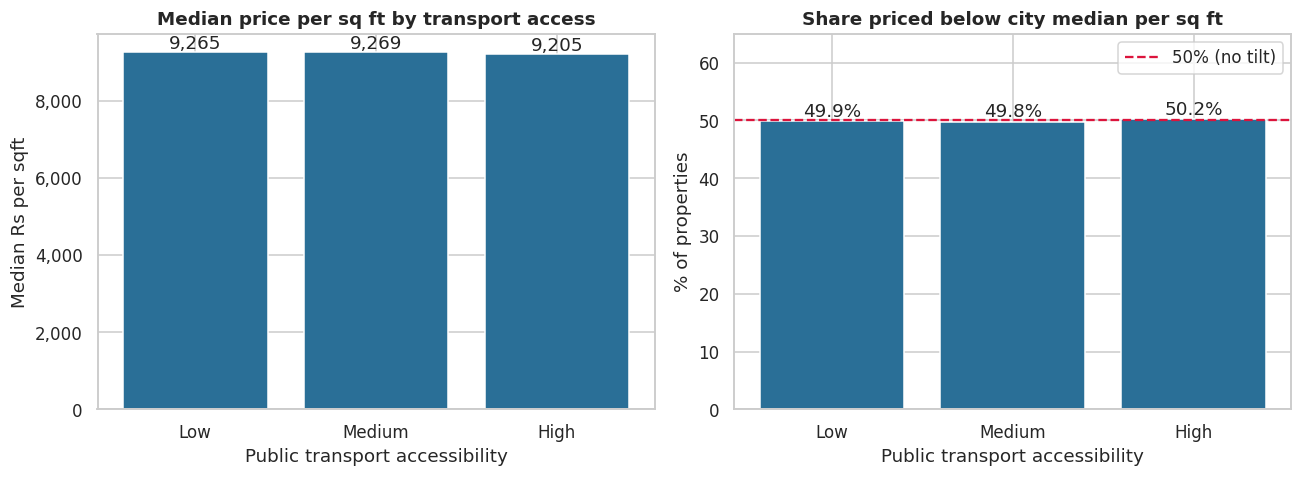

ANOVA Public_Transport_Accessibility -> Price_per_SqFt_Rs (log): F = 0.21, p = 0.8135, eta squared = 0.00000 (0.0002% of variation explained)
Chi-square (transport vs below-city-median): chi2 = 3.60, p = 0.165


In [21]:
levels = ["Low", "Medium", "High"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

med = df.groupby("Public_Transport_Accessibility")["Price_per_SqFt_Rs"].median().loc[levels]
axes[0].bar(levels, med.values, color=ACCENT)
for i, v in enumerate(med.values):
    axes[0].text(i, v + 80, f"{v:,.0f}", ha="center")
axes[0].set(title="Median price per sq ft by transport access", xlabel="Public transport accessibility", ylabel="Median Rs per sqft")
axes[0].yaxis.set_major_formatter(rs)

share = df.groupby("Public_Transport_Accessibility")["Below_City_Median"].mean().loc[levels] * 100
axes[1].bar(levels, share.values, color=ACCENT)
axes[1].axhline(50, color="crimson", ls="--", label="50% (no tilt)")
for i, v in enumerate(share.values):
    axes[1].text(i, v + 0.8, f"{v:.1f}%", ha="center")
axes[1].set(title="Share priced below city median per sq ft", xlabel="Public transport accessibility",
            ylabel="% of properties", ylim=(0, 65))
axes[1].legend()
plt.tight_layout(); plt.show()

anova_eta(df, "Public_Transport_Accessibility", "Price_per_SqFt_Rs", log=True)
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["Public_Transport_Accessibility"], df["Below_City_Median"]))
print(f"Chi-square (transport vs below-city-median): chi2 = {chi2:.2f}, p = {p:.3f}")

**Takeaway**
- Properties with high, medium and low transport access have the same median price per sq ft (within about 1%), and the same share priced below their city median (about 50% in each group: 50.2% high, 49.9% low, 49.8% medium). Both tests are non-significant.
- **Transport access gives no pricing signal and no investment edge in this data.** In a real market, well-connected locations normally command a premium, so an advisor built on real data would treat this very differently.

## 4. Summary and Investment Implications

### What the data shows
| Area | Finding |
|---|---|
| Price | Spread evenly from 10 to 500 lakhs, no skew, no outliers |
| Price per sq ft | Right-skewed, median about Rs 9,200 per sq ft; it falls with size only because it is price divided by size |
| Size vs price | No relationship (r = -0.003) |
| State and city | Differences of a few percent, not statistically significant, explain well under 0.1% of variation |
| Furnishing, amenities, transport | No price premium and no relative-value tilt |
| Correlation matrix | The only strong relationships are the formula-driven ones involving price per sq ft |

### What this means for an investment advisor
1. **Nothing in the listed features predicts price.** Any "good vs bad investment" rule built on these columns will be a screening rule, not a forecast of appreciation or rent.
2. **The only measurable value signal is relative price per sq ft**, and it is driven mostly by size. Large properties will rank as "good value" and small ones as "poor value" because of arithmetic, not because of the market.
3. **Because the market charges nothing extra for amenities, transport, furnishing or parking in this data**, a buyer comparing two properties at the same price should simply take the one with more of them. That is a valid statement about this dataset, but should not be presented as a general real estate rule.
4. **City and state rankings should not be shown as findings.** The differences are within noise.

### Data caveats to mention in the report
- Floor number exceeds total floors in 46.5% of rows; 44% of "Under Construction" listings are over 5 years old.
- BHK is unrelated to size; the same 500 locality names appear in all 42 cities.
- The flat distributions and near-zero correlations suggest the data was generated randomly (a simulated dataset). Conclusions are valid for **this dataset**, and should be worded that way rather than as statements about the Indian housing market.

### Handoff to the Streamlit stage
`data/housing_clean.csv.gz` holds the cleaned data plus all engineered features, ready to load. The Streamlit dashboard reads this file. It adds one more column, a size-adjusted value index (price per sq ft divided by the median for the same city and similar size band), because `Below_City_Median` above inherits the size bias described in Q4.